In [64]:
#Importação Necessária
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import ScalarFormatter
from matplotlib import rcParams
rcParams["font.size"] = 15
rcParams["figure.figsize"] = (7, 6)
from scipy.interpolate import interp1d
from scipy.integrate import trapezoid
import numpy as np

#import solver related modules
from MCEq.core import MCEqRun
import MCEq.config as config
#import primary model choices
import crflux.models as pm

In [65]:
interaction_models = (
    'EPOSLHCR',
    'QGSJETIII',
    'SIBYLL23E',
    'SIBYLL21',
)

cr_energy = {"auger": 1e10, "icecube": 1e8}
h_obs = {"auger": 1425, "icecube": 2835}
theta_deg = {"auger": 67, "icecube": 13}    

lepton_spectra = {}
height_grid = {}

In [66]:

for experiment in ("auger", "icecube"):
    if experiment not in lepton_spectra:
        lepton_spectra[experiment] = {}
    for interaction_model in interaction_models:
        if interaction_model in lepton_spectra[experiment]:
            print ("skipping", interaction_model)
            continue
        lepton_spectra[experiment][interaction_model] = {}
        for prim in ("proton", "iron"):
            print("=== processing", experiment, interaction_model, prim, "===")
            spectra = lepton_spectra[experiment][interaction_model][prim] = {}

            config.h_obs = h_obs[experiment]
            mceq_run = MCEqRun(
                interaction_model,
                primary_model=(pm.HillasGaisser2012, 'H3a'),
                theta_deg=theta_deg[experiment],
            )
            mceq_run.set_density_model(
                {
                    "icecube": ("MSIS00_IC", ("SouthPole", "January")),
                    "auger": ("CORSIKA", ("BK_USStd", None)),
                }[experiment]
            )

            a = {"proton": 1, "iron": 56}[prim]
            if prim == 'proton':
                mceq_run.set_single_primary_particle(
                    cr_energy[experiment], pdg_id = 2212)
            else:
                mceq_run.set_single_primary_particle(
                    cr_energy[experiment], corsika_id = 5626)

            Xvec = np.arange(1, mceq_run.density_model.max_X, 5)
            if experiment not in height_grid:
                height_grid[experiment] = (Xvec, mceq_run.density_model.s_lX2h(np.log(Xvec))/1e2)

            mceq_run.solve(int_grid=Xvec, grid_var="X")

            # muons
            spectra["egrid"] = mceq_run.e_grid
            for t in ("total", "conv", "pr"):
                spectra["mu_" + t] = (
                    mceq_run.get_solution(t + '_mu+', 0) +
                    mceq_run.get_solution(t + '_mu-', 0)
                )

            mu_long = np.empty_like(Xvec)
            for idx, X in enumerate(Xvec):
                y = (mceq_run.get_solution("total_mu+", 0, grid_idx=idx) +
                     mceq_run.get_solution("total_mu-", 0, grid_idx=idx))
                mask = mceq_run.e_grid >= 1.0

                mu_long[idx] = trapezoid(
                    y[mask],
                    mceq_run.e_grid[mask]
                )
            spectra["mu_long"] = mu_long

            if experiment == "icecube":
                for n in ("numu", "nue", "nutau"):
                    for t in ("total", "conv", "pr"):
                        # since there are no conventional tau neutrinos, prompt=total
                        if n == "nutau" and t != "total": continue
                        spectra[n + "_" + t] = (
                            mceq_run.get_solution(t + '_' + n, 0) +
                            mceq_run.get_solution(t + '_anti' + n, 0)
                        )

=== processing auger EPOSLHCR proton ===
MCEqRun::set_interaction_model(): EPOSLHCR
ParticleManager::_init_default_tracking(): Initializing default tracking categories (pi, K, mu)
MatrixBuilder::_fill_matrices(): No interactions by D- ((-411, 0)).
MatrixBuilder::_fill_matrices(): No interactions by D+ ((411, 0)).
MatrixBuilder::_fill_matrices(): No interactions by Dbar0 ((-421, 0)).
MatrixBuilder::_fill_matrices(): No interactions by D0 ((421, 0)).
MatrixBuilder::_fill_matrices(): No interactions by D_s- ((-431, 0)).
MatrixBuilder::_fill_matrices(): No interactions by D_s+ ((431, 0)).
MCEqRun::set_density_model(): Setting density profile to CORSIKA ('BK_USStd', None)
MCEqRun::set_primary_model(): Primary model set to Hillas-Gaisser (H3a)
MCEqRun::set_density_model(): Setting density profile to CORSIKA ('BK_USStd', None)
=== processing auger EPOSLHCR iron ===
MCEqRun::set_interaction_model(): EPOSLHCR
ParticleManager::_init_default_tracking(): Initializing default tracking categories (p

In [67]:
def model_color(name):
    model_colors = {"EPOSLHCR": "green",
                    "QGSJETIII" : "b",
                    "SIBYLL23E" : "r",
                    "SIBYLL21": "r"}
    for k,v in model_colors.items():
        if name.startswith(k):
            return v

def model_linestyle(name):
    if name in ("EPOSLHCR", "SIBYLL23E", "QGSJETIII"):
        return "-"
    else:
        return ":"

auger 2207 gcm-2
icecube 716 gcm-2


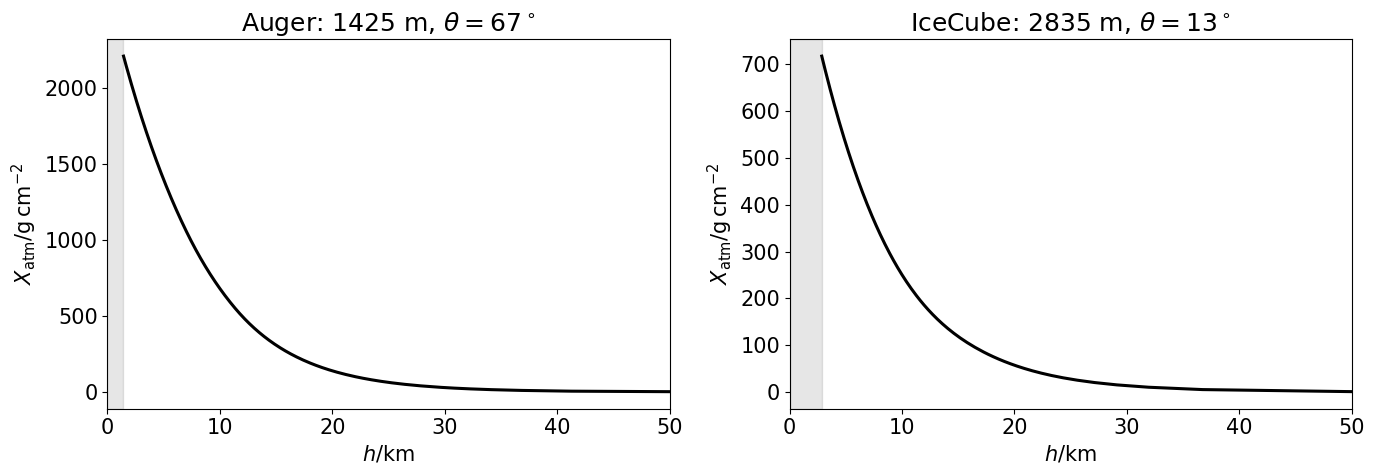

In [68]:
# Parametrizações Atmosféricas
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

for ax, experiment in zip(axes, ("auger", "icecube")):
    X, h = height_grid[experiment]
    ax.set_title({
        "auger": r"Auger: 1425 m, $\theta = 67^\circ$",
        "icecube": r"IceCube: 2835 m, $\theta = 13^\circ$",
    }[experiment])
    ax.plot(h/1e3, X, color="black", lw=2.2)
    ax.axvspan(0, h_obs[experiment]/1e3, color="0.2", alpha=0.12, zorder=0)


    x_ground = interp1d(h, X)(h_obs[experiment] + 20.)
    print("%s %.0f gcm-2" % (experiment, x_ground))

    ax.set_xlim(0, 50)
    ax.set_xlabel("$h$/km")
    ax.set_ylabel("$X_\\mathrm{atm}/\\mathrm{g\\,cm^{-2}}$")

plt.tight_layout()
plt.show()



auger proton h_mu_max 7.0 km
auger iron h_mu_max 7.5 km
ratio 1.352660238563623
auger proton h_mu_max 7.3 km
auger iron h_mu_max 7.8 km
ratio 1.4053727114164247
auger proton h_mu_max 7.5 km
auger iron h_mu_max 8.0 km
ratio 1.3708929515628163
auger proton h_mu_max 7.8 km
auger iron h_mu_max 8.3 km
ratio 1.5131897701489494
icecube proton h_mu_max 2.9 km
icecube iron h_mu_max 2.9 km
ratio 1.6183450724299608
icecube proton h_mu_max 2.9 km
icecube iron h_mu_max 2.9 km
ratio 1.6624846797256705
icecube proton h_mu_max 2.9 km
icecube iron h_mu_max 2.9 km
ratio 1.5644003082964122
icecube proton h_mu_max 2.9 km
icecube iron h_mu_max 2.9 km
ratio 1.6581823798339312
auger avg h_mu_max 7.7 km
icecube avg h_mu_max 2.9 km


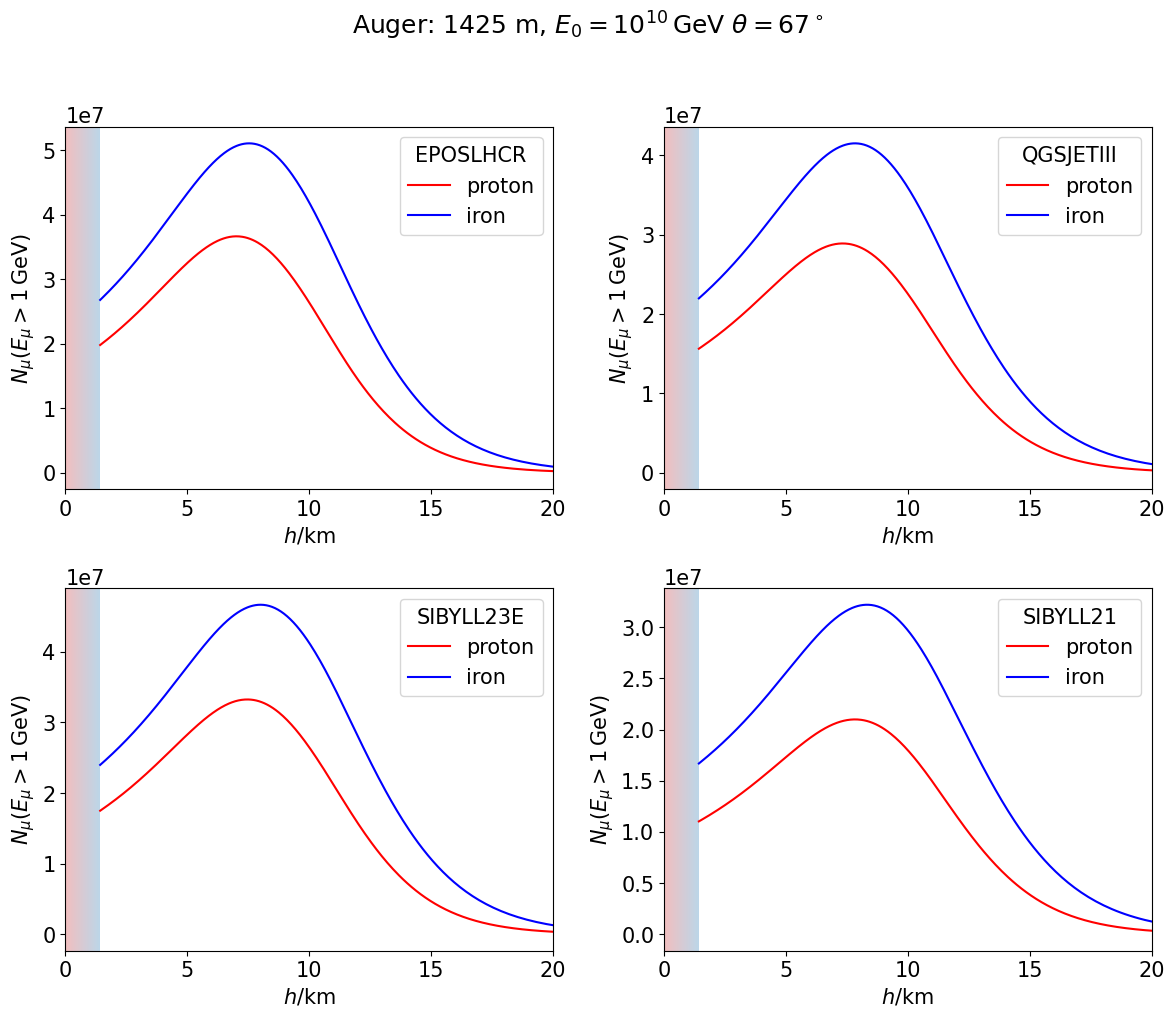

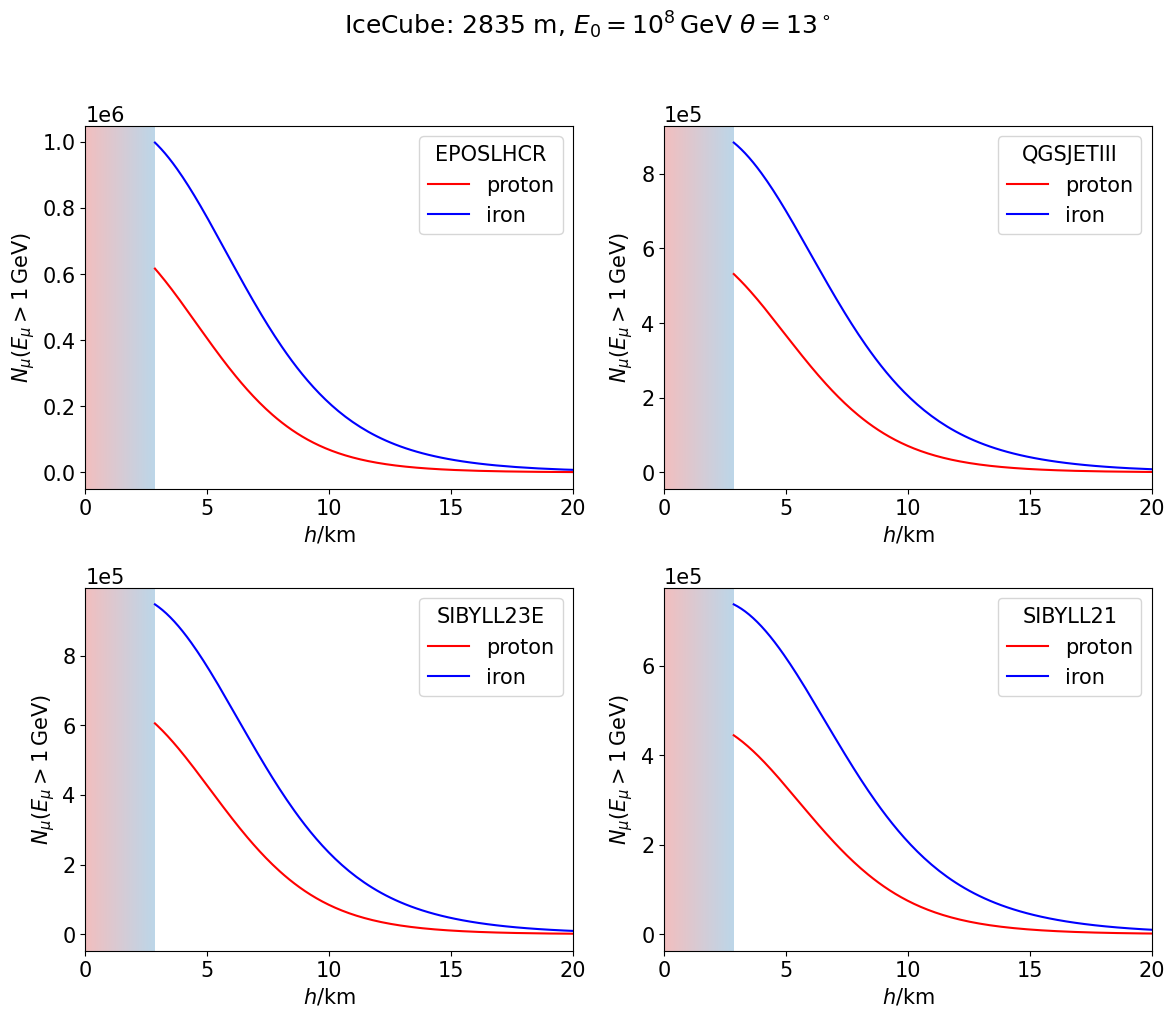

In [69]:
# longitudinal
h_mu_max = {"auger": 0.0, "icecube": 0.0}

for experiment in lepton_spectra:
    X, h = height_grid[experiment]

    fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=False, sharey=False)
    axes = axes.flatten()
    i_ax = 0

    for interaction_model in interaction_models:
        if interaction_model not in lepton_spectra[experiment]:
            continue

        ax = axes[i_ax]
        i_ax += 1

        prim_spectra = lepton_spectra[experiment][interaction_model]

        for prim, spectra in prim_spectra.items():
            y = spectra["mu_long"]
            color = {"proton": "r", "iron": "b"}[prim]
            ax.plot(h/1e3, y, color=color, label=prim)
            hm = h[np.argmax(y)]
            h_mu_max[experiment] += hm
            print(f"{experiment} {prim} h_mu_max {hm/1e3:.1f} km")

        ratio = prim_spectra["iron"]["mu_long"][-1] / prim_spectra["proton"]["mu_long"][-1]
        print("ratio", ratio)

        ax.set_xlim(0, 20)
        ax.legend(title=interaction_model)
        #ax.axvspan(0, h_obs[experiment]/1e3, color="k", alpha=0.2, zorder=1)
        ax.set_xlabel("$h$/km")
        ax.set_ylabel("$N_\\mu(E_\\mu > 1\\,\\mathrm{GeV})$")
        ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
        # faixa de h=0 até h_obs
        x0, x1 = 0, h_obs[experiment]/1e3
        y0, y1 = ax.get_ylim()

        cmap_rb = LinearSegmentedColormap.from_list("rb_grad", ["#d62728", "#1f77b4"])
        grad = np.linspace(0, 1, 256).reshape(1, -1)  # degradê horizontal

        ax.imshow(
            grad,
            extent=[x0, x1, y0, y1],
            origin="lower",
            aspect="auto",
            cmap=cmap_rb,
            alpha=0.30,
            zorder=0
        )

    for j in range(i_ax, len(axes)):
        axes[j].set_visible(False)

    fig.suptitle({
        "auger": r"Auger: 1425 m, $E_0 = 10^{10}\,$GeV $\theta = 67^\circ$",
        "icecube": r"IceCube: 2835 m, $E_0 = 10^8\,$GeV $\theta = 13^\circ$",
    }[experiment], y=1.02)

    plt.tight_layout()

for k, v in h_mu_max.items():
    h_mu_max[k] = v / (2 * len(interaction_models))
    print("%s avg h_mu_max %.1f km" % (k, h_mu_max[k]/1e3))


C:\Users\tiago\AppData\Local\Temp\ipykernel_23804\3314948172.py:25: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k-" (-> color='k'). The keyword argument will take precedence.
  ax.plot(x, y1, "k-", color=color, lw=2, label=label + " total")
C:\Users\tiago\AppData\Local\Temp\ipykernel_23804\3314948172.py:26: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k:" (-> color='k'). The keyword argument will take precedence.
  ax.plot(x, y2, "k:", color=color, label=label + " prompt")


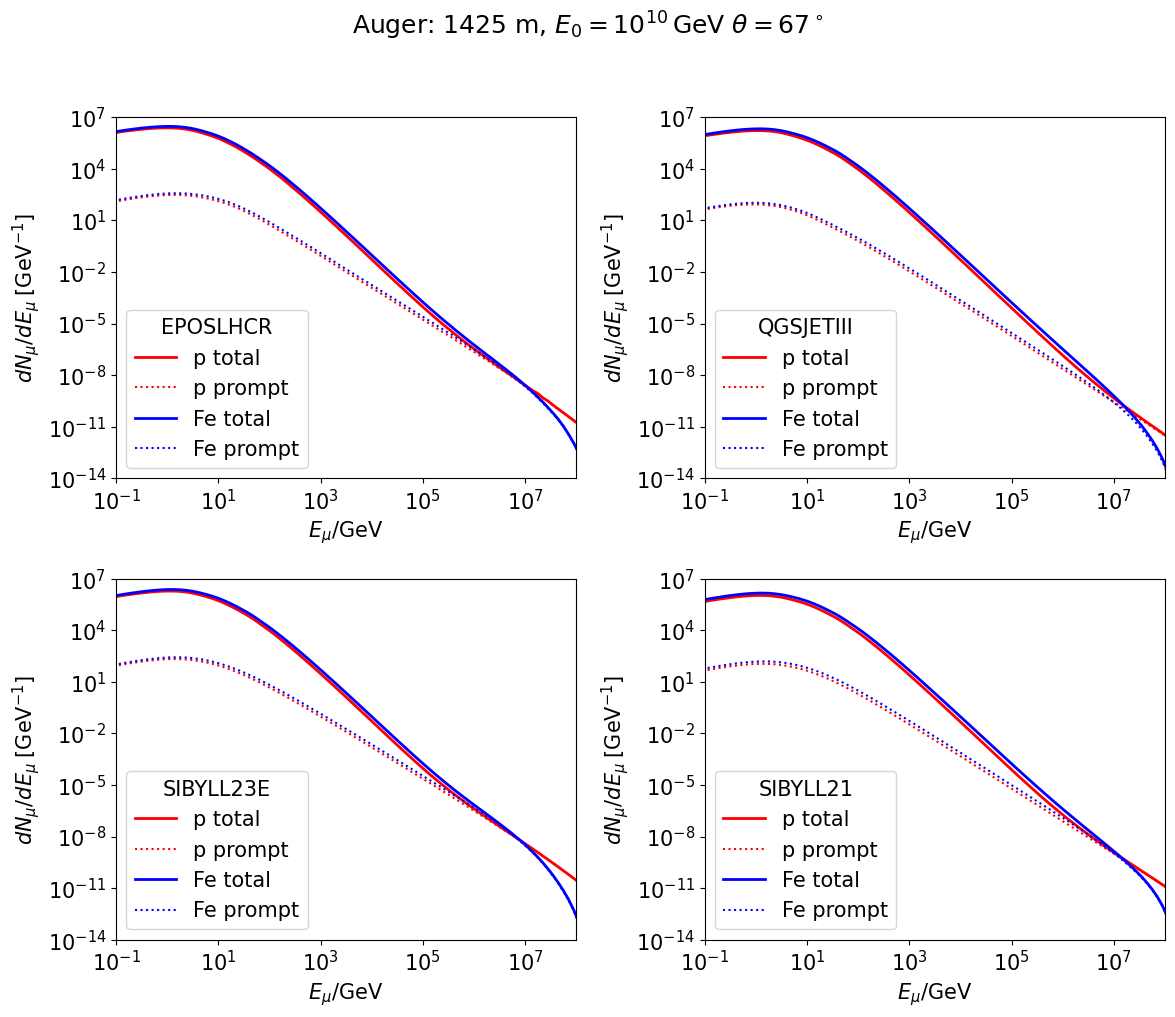

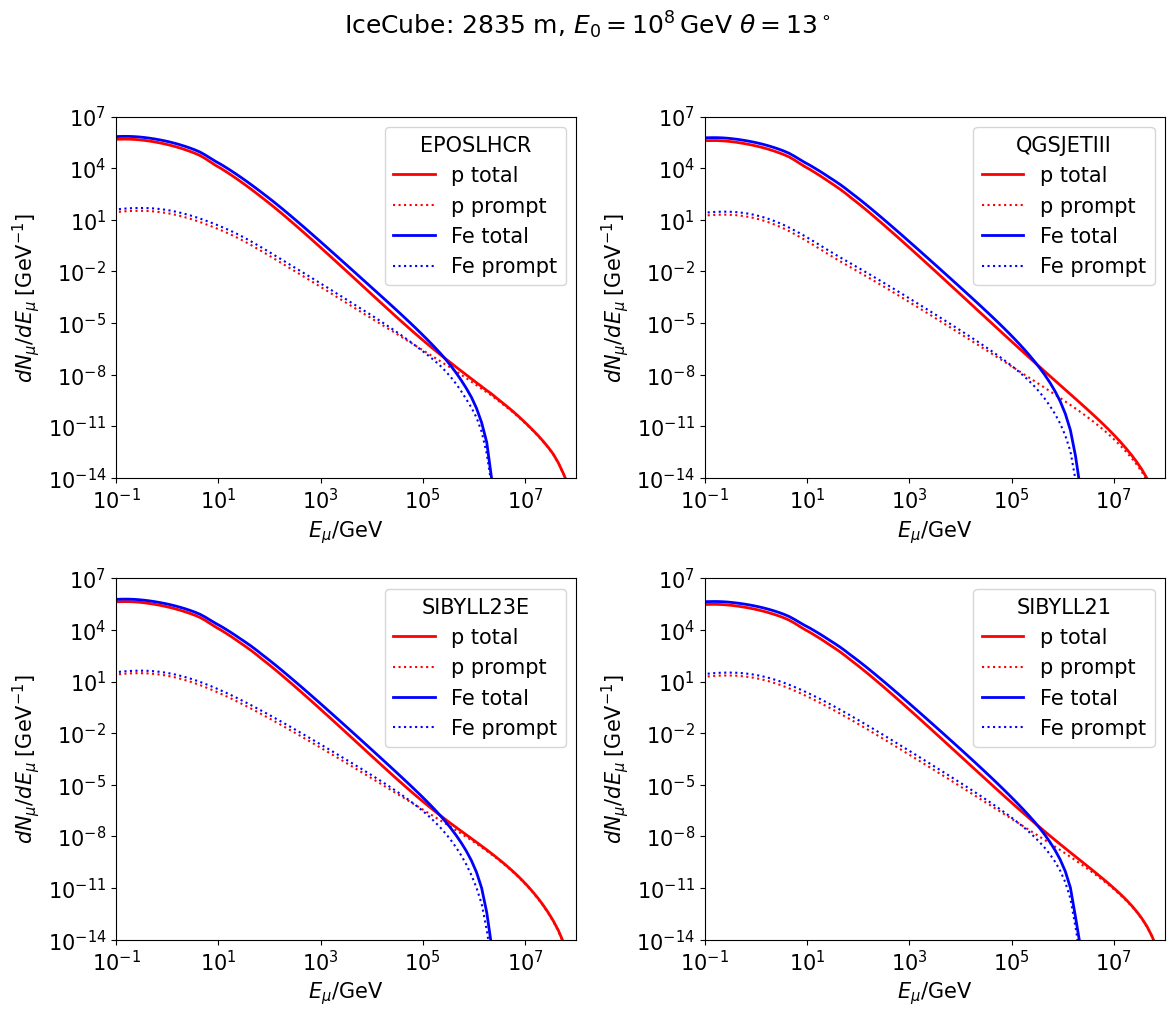

In [70]:
# muon spectra 1
for experiment in lepton_spectra:
    fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=False, sharey=False)
    axes = axes.flatten()
    i_ax = 0

    for interaction_model in interaction_models:
        if interaction_model not in lepton_spectra[experiment]:
            continue

        if i_ax >= len(axes):
            break  # mantém 2x2

        ax = axes[i_ax]
        i_ax += 1

        prim_spectra = lepton_spectra[experiment][interaction_model]
        for prim, spectra in prim_spectra.items():
            x = spectra["egrid"]
            y1 = spectra["mu_total"]
            y2 = spectra["mu_pr"]
            color = {"proton": "r", "iron": "b"}[prim]
            label = {"proton": "p", "iron": "Fe"}[prim]

            ax.plot(x, y1, "k-", color=color, lw=2, label=label + " total")
            ax.plot(x, y2, "k:", color=color, label=label + " prompt")
            

        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlim(.1, 1e8)
        ax.set_ylim(1e-14, 1e7)
        ax.set_xlabel(r"$E_\mu$/GeV")
        ax.set_ylabel(r"$dN_\mu/dE_\mu\;[\mathrm{GeV}^{-1}]$")
        ax.legend(title=interaction_model)

    for j in range(i_ax, len(axes)):
        axes[j].set_visible(False)

    fig.suptitle({
        "auger": r"Auger: 1425 m, $E_0 = 10^{10}\,$GeV $\theta = 67^\circ$",
        "icecube": r"IceCube: 2835 m, $E_0 = 10^8\,$GeV $\theta = 13^\circ$",
    }[experiment], y=1.02)

    plt.tight_layout()
    plt.show()


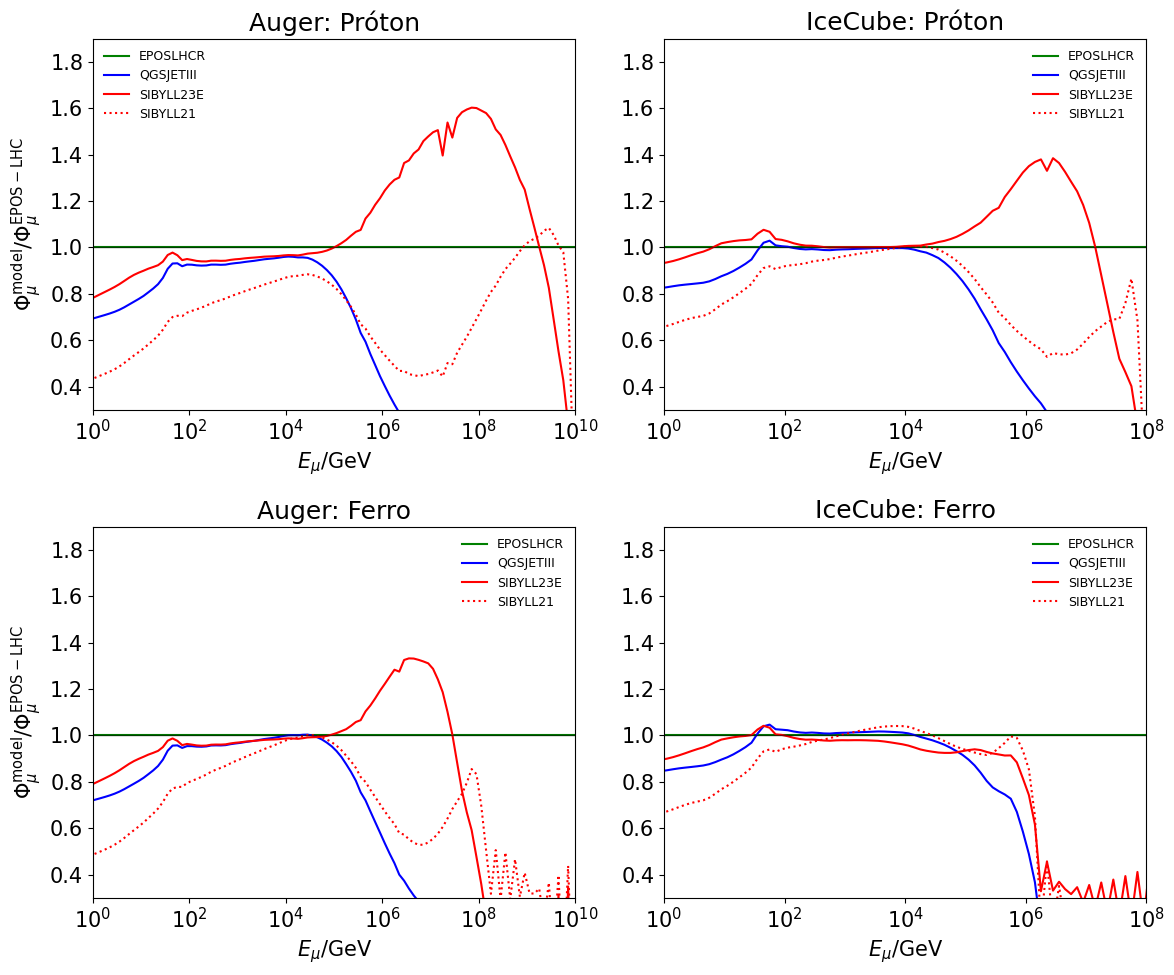

In [71]:
# muon spectra 2: razão em relação ao EPOS-LHC para próton e ferro
fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharey=False)

for row, prim in enumerate(("proton", "iron")):
    for col, experiment in enumerate(("auger", "icecube")):
        ax = axes[row, col]

        ax.set_title({
            ("auger", "proton"): r"Auger: Próton",
            ("auger", "iron"): r"Auger: Ferro",
            ("icecube", "proton"): r"IceCube: Próton",
            ("icecube", "iron"): r"IceCube: Ferro",
        }[(experiment, prim)])

        ref = lepton_spectra[experiment]["EPOSLHCR"][prim]
        x_ref = ref["egrid"]
        y_ref = ref["mu_total"]

        for interaction_model in interaction_models:
            if interaction_model not in lepton_spectra[experiment]:
                continue

            spectra = lepton_spectra[experiment][interaction_model][prim]
            x = spectra["egrid"]
            y = spectra["mu_total"]

            assert np.all(x == x_ref)

            mask = y_ref > 0

            ax.plot(
                x[mask],
                y[mask] / y_ref[mask],
                linestyle=model_linestyle(interaction_model),
                color=model_color(interaction_model),
                label=interaction_model
            )

        ax.axhline(1.0, color="k", lw=1, alpha=0.5)
        ax.set_xscale("log")
        ax.set_xlim(1, cr_energy[experiment])
        ax.set_ylim(0.3, 1.9)
        ax.set_xlabel(r"$E_\mu$/GeV")

        if col == 0:
            ax.set_ylabel(r"$\Phi_\mu^\mathrm{model} / \Phi_\mu^\mathrm{EPOS-LHC}$")

        ax.legend(loc="best", fontsize=9, frameon=False)

plt.tight_layout()
plt.show()

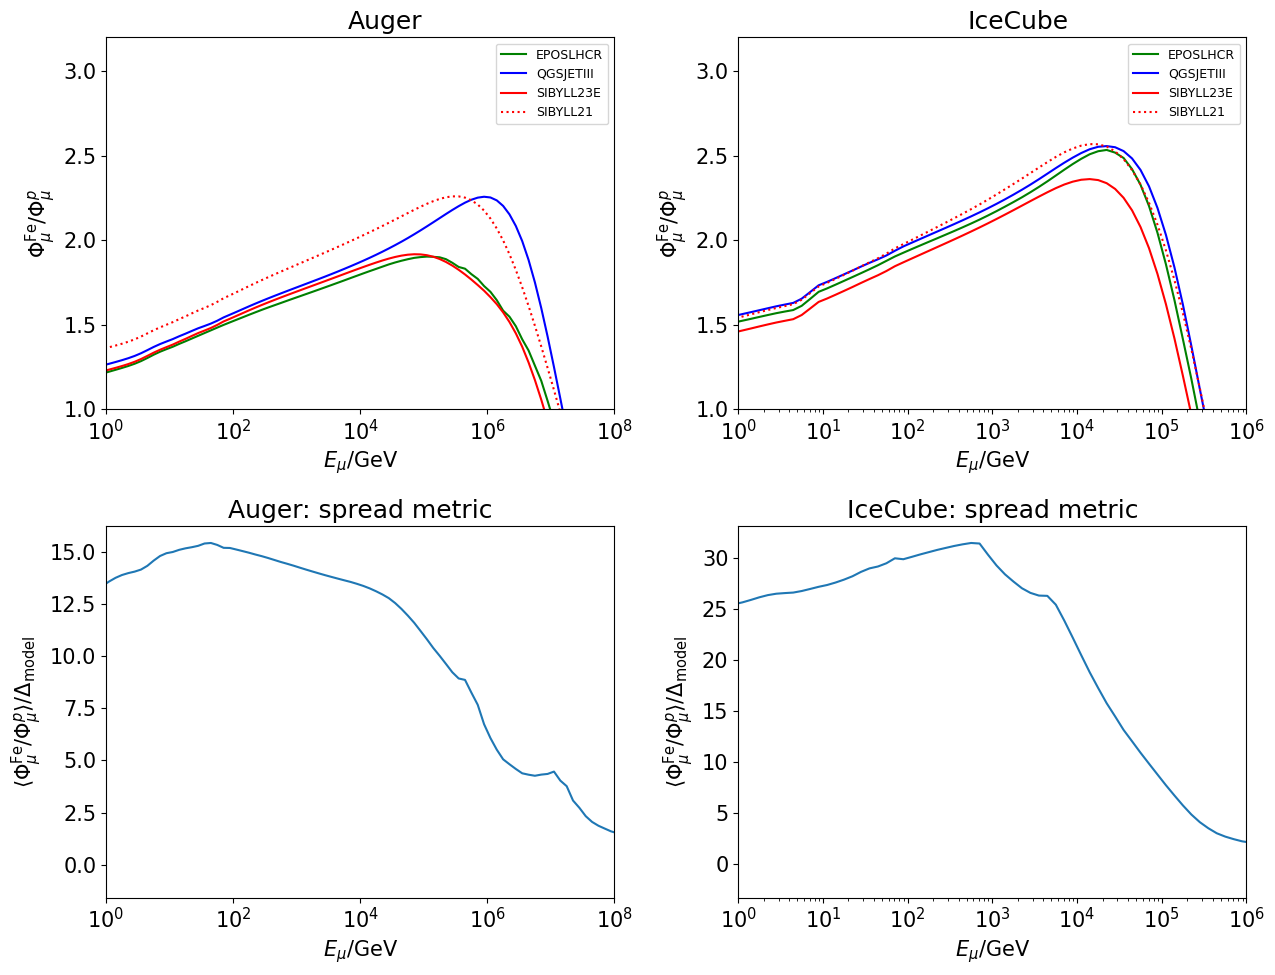

In [72]:
# muon spectra ratios
fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharex=False, sharey=False)

for col, experiment in enumerate(("auger", "icecube")):
    ratios = []

    # painel superior: iron/proton por modelo
    ax_top = axes[0, col]
    ax_top.set_title({
        "auger": r"Auger",
        "icecube": r"IceCube",
    }[experiment], x=0.55)

    xproton = None
    for interaction_model in interaction_models:
        if interaction_model not in lepton_spectra[experiment]:
            continue

        prim_spectra = lepton_spectra[experiment][interaction_model]
        ratio = prim_spectra["iron"]["mu_total"] / prim_spectra["proton"]["mu_total"]
        xiron = prim_spectra["iron"]["egrid"]
        xproton = prim_spectra["proton"]["egrid"]
        assert(np.all(xiron == xproton))

        ratios.append(ratio)
        ax_top.plot(
            xproton, ratio,
            color=model_color(interaction_model),
            ls=model_linestyle(interaction_model),
            label=interaction_model
        )

    ax_top.set_xscale("log")
    ax_top.set_xlim(1, cr_energy[experiment]/1e2)
    ax_top.set_ylim(1, 3.2)
    ax_top.set_xlabel(r"$E_\mu$/GeV")
    ax_top.set_ylabel(r"$\Phi_\mu^{\mathrm{Fe}}/\Phi_\mu^{p}$")
    ax_top.legend(loc="best", fontsize=9)

    # painel inferior: (média razão) / (espalhamento entre modelos)
    ax_bot = axes[1, col]
    ax_bot.set_title({
        "auger": r"Auger: spread metric",
        "icecube": r"IceCube: spread metric",
    }[experiment])

    m = np.mean(ratios, axis=0)
    d = np.zeros_like(m)
    for r in ratios:
        a = np.abs(r - m)
        d[d < a] = a[d < a]

    ax_bot.plot(xproton, m / d)
    ax_bot.set_xscale("log")
    ax_bot.set_xlim(1, cr_energy[experiment]/1e2)
    ax_bot.set_xlabel(r"$E_\mu$/GeV")
    ax_bot.set_ylabel(r"$\langle \Phi_\mu^{\mathrm{Fe}}/\Phi_\mu^p \rangle / \Delta_\mathrm{model}$")

plt.tight_layout()
plt.show()


C:\Users\tiago\AppData\Local\Temp\ipykernel_23804\1095181740.py:25: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k-" (-> color='k'). The keyword argument will take precedence.
  ax.plot(x, y1, "k-", color=color, lw=2, label=label + " total")
C:\Users\tiago\AppData\Local\Temp\ipykernel_23804\1095181740.py:26: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k:" (-> color='k'). The keyword argument will take precedence.
  ax.plot(x, y2, "k:", color=color, label=label + " prompt")


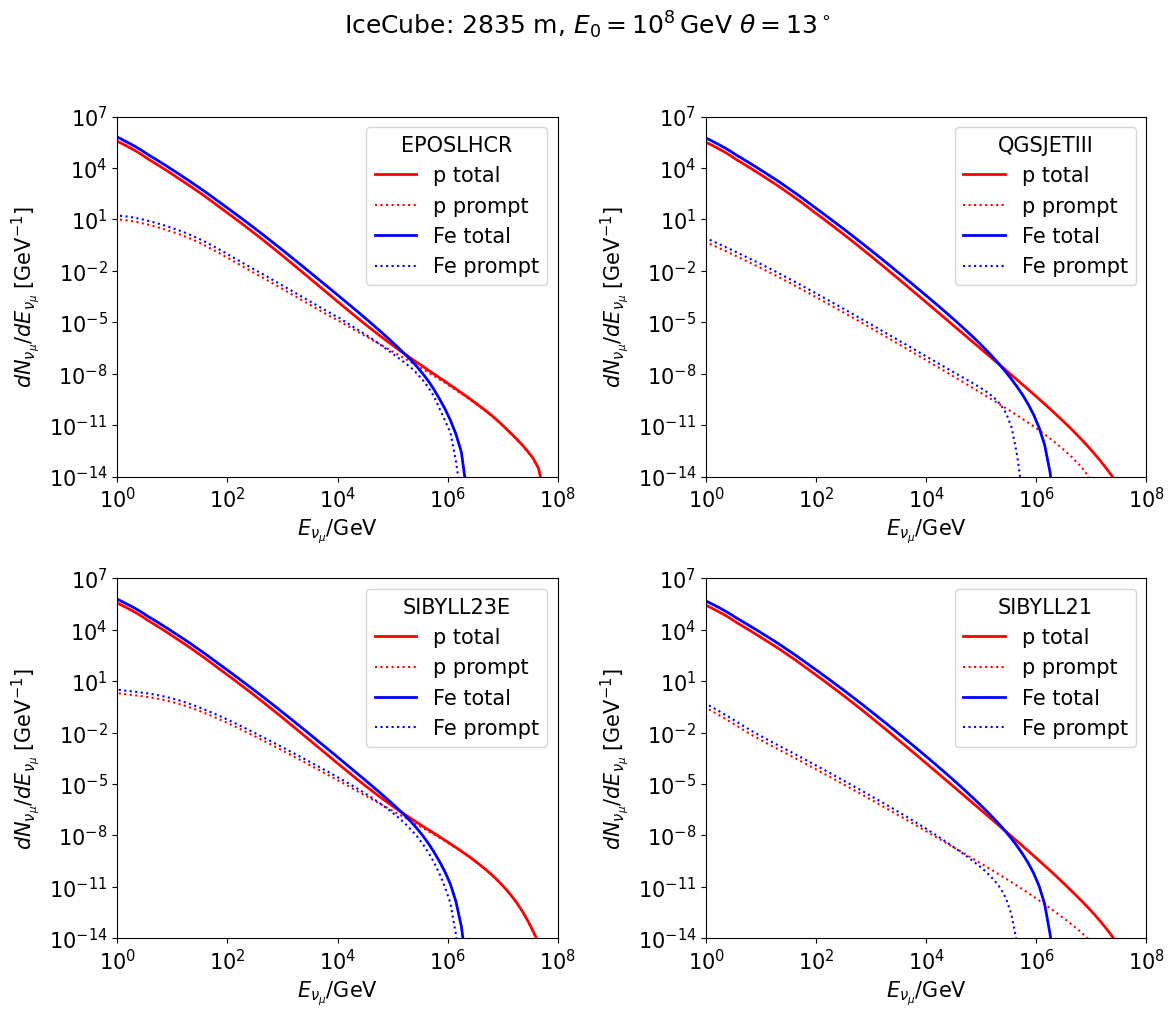

In [73]:
# neutrino spectra
fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=False, sharey=False)
axes = axes.flatten()
i_ax = 0

for interaction_model in interaction_models:
    if interaction_model not in lepton_spectra["icecube"]:
        continue
    if i_ax >= len(axes):
        break  # mantém 2x2

    ax = axes[i_ax]
    i_ax += 1

    prim_spectra = lepton_spectra["icecube"][interaction_model]


    for prim, spectra in prim_spectra.items():
        x = spectra["egrid"]
        y1 = spectra["numu_total"]
        y2 = spectra["numu_pr"]
        color = {"proton": "r", "iron": "b"}[prim]
        label = {"proton": "p", "iron": "Fe"}[prim]

        ax.plot(x, y1, "k-", color=color, lw=2, label=label + " total")
        ax.plot(x, y2, "k:", color=color, label=label + " prompt")

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(1, 1e8)
    ax.set_ylim(1e-14, 1e7)
    ax.set_xlabel(r"$E_{\nu_\mu}$/GeV")
    ax.set_ylabel(r"$dN_{\nu_\mu}/dE_{\nu_\mu}\;[\mathrm{GeV}^{-1}]$")
    ax.legend(title=interaction_model)

for j in range(i_ax, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(r"IceCube: 2835 m, $E_0 = 10^8\,$GeV $\theta = 13^\circ$", y=1.02)
plt.tight_layout()
plt.show()


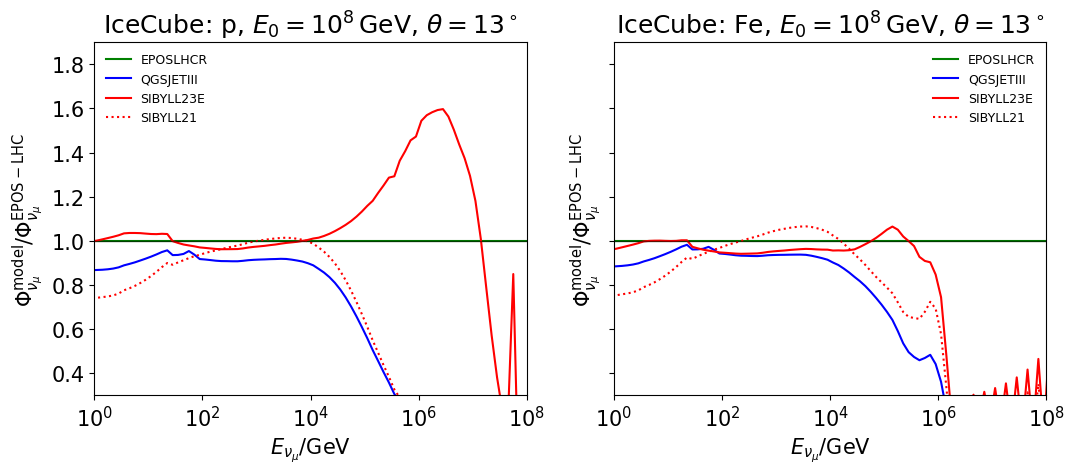

In [74]:
# neutrino spectra ratios relative to EPOS-LHC
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)

for ax, prim in zip(axes, ("proton", "iron")):
    ax.set_title({
        "proton": r"IceCube: p, $E_0 = 10^8\,$GeV, $\theta = 13^\circ$",
        "iron": r"IceCube: Fe, $E_0 = 10^8\,$GeV, $\theta = 13^\circ$",
    }[prim])

    ref = lepton_spectra["icecube"]["EPOSLHCR"][prim]
    x_ref = ref["egrid"]
    y_ref = ref["numu_total"]

    for interaction_model in interaction_models:
        if interaction_model not in lepton_spectra["icecube"]:
            continue

        spectra = lepton_spectra["icecube"][interaction_model][prim]
        x = spectra["egrid"]
        y = spectra["numu_total"]

        assert np.all(x == x_ref)

        mask = y_ref > 0

        ax.plot(
            x[mask],
            y[mask] / y_ref[mask],
            linestyle=model_linestyle(interaction_model),
            color=model_color(interaction_model),
            label=interaction_model
        )

    ax.axhline(1.0, color="k", lw=1, alpha=0.5)
    ax.set_xscale("log")
    ax.set_xlim(1, 1e8)
    ax.set_ylim(0.3, 1.9)
    ax.set_xlabel(r"$E_{\nu_\mu}$/GeV")
    ax.set_ylabel(r"$\Phi_{\nu_\mu}^{\mathrm{model}}/\Phi_{\nu_\mu}^{\mathrm{EPOS-LHC}}$")
    ax.legend(loc="best", fontsize=9, frameon=False)

plt.tight_layout()
plt.show()